Loading dataset...
Rows used: 280,660
Represented exams (sum of count): 2,392,998

Calculating weighted PCA...
Explained variance by PC1 + PC2: 27.21%
Explained variance by PC1 + PC2 + PC3: 33.78%


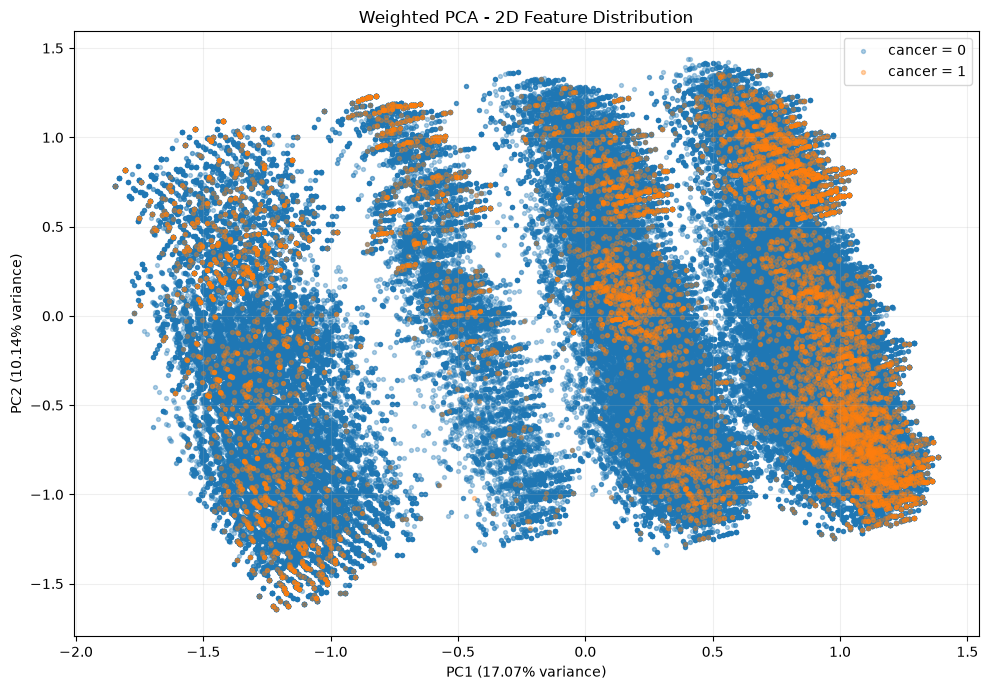

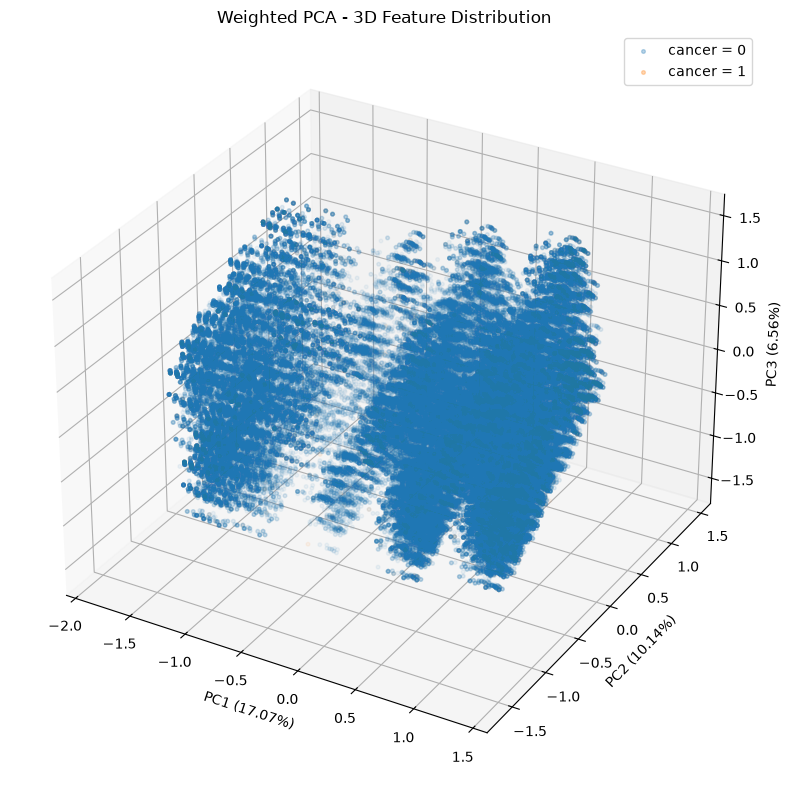


Preparing weighted sample for t-SNE...
Running t-SNE. This may take some time...


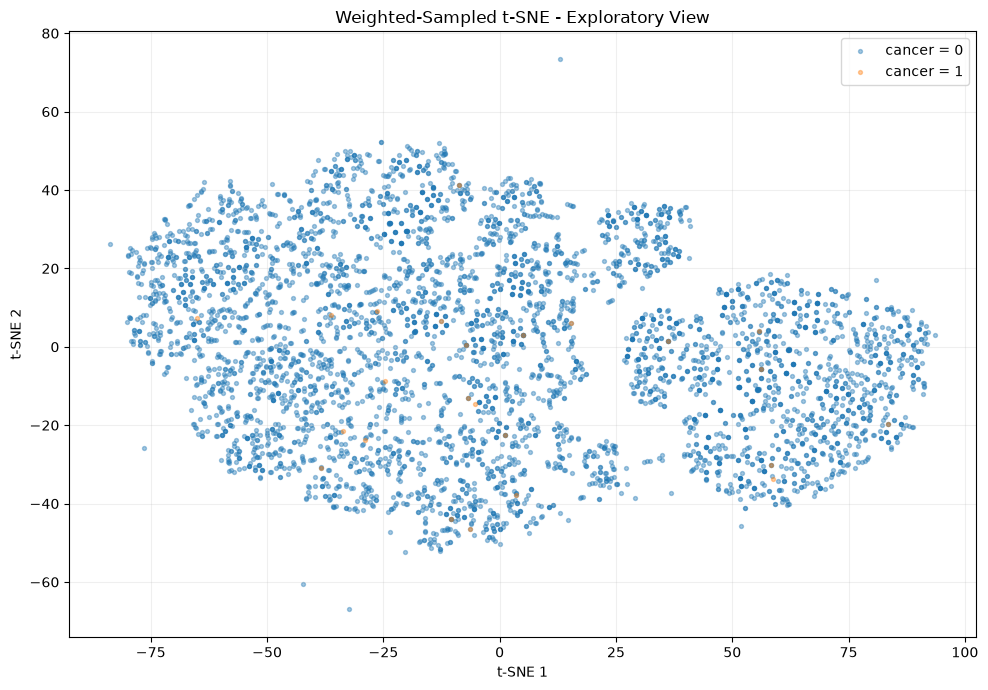


Visualization completed.
Generated files:
- pca_2d_distribution.png
- pca_3d_distribution.png
- tsne_2d_distribution.png
- pca_2d_coordinates.csv


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import OneHotEncoder
from sklearn.manifold import TSNE

# ==================================================
# Configuration
# ==================================================

INPUT_FILE = "risk_filtered.csv"

TARGET = "cancer"
WEIGHT_COLUMN = "count"

FEATURES = [
    "agegrp",
    "bmi",
    "agefirst",
    "menopaus",
    "surgmeno",
    "hrt",
    "nrelbc",
    "density",
    "brstproc",
    "lastmamm"
]

# Number of rows sampled for optional t-SNE
TSNE_SAMPLE_SIZE = 5000

RANDOM_STATE = 42

# ==================================================
# Load Dataset
# ==================================================

print("Loading dataset...")

df = pd.read_csv(INPUT_FILE)

required_columns = FEATURES + [TARGET, WEIGHT_COLUMN]
missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Keep only required columns
df = df[required_columns].copy()

# Remove rows with missing target or invalid weights
df = df.dropna(subset=[TARGET, WEIGHT_COLUMN])
df = df[df[WEIGHT_COLUMN] > 0].copy()

# Remove rows with missing feature values for this visualization
# This is only for visualization, not the final preprocessing decision.
df = df.dropna(subset=FEATURES).copy()

df[WEIGHT_COLUMN] = df[WEIGHT_COLUMN].astype(float)

print(f"Rows used: {len(df):,}")
print(f"Represented exams (sum of count): {df[WEIGHT_COLUMN].sum():,.0f}")

# ==================================================
# Encode Features
# ==================================================

# Treat all selected features as categorical
X_categories = df[FEATURES].astype(str)

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_encoded = encoder.fit_transform(X_categories)

feature_names = encoder.get_feature_names_out(FEATURES)

X = np.asarray(X_encoded, dtype=np.float64)
weights = df[WEIGHT_COLUMN].to_numpy(dtype=np.float64)

# Target labels
y = df[TARGET].astype(str).to_numpy()

# ==================================================
# Weighted PCA
# ==================================================

print("\nCalculating weighted PCA...")

# Weighted mean
weighted_mean = np.average(X, axis=0, weights=weights)

# Center data
X_centered = X - weighted_mean

# Weighted covariance matrix
weighted_cov = (
    X_centered.T @ (X_centered * weights[:, None])
) / weights.sum()

# Eigen decomposition
eigenvalues, eigenvectors = np.linalg.eigh(weighted_cov)

# Sort components by descending eigenvalue
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Project into 2D and 3D
X_pca_2d = X_centered @ eigenvectors[:, :2]
X_pca_3d = X_centered @ eigenvectors[:, :3]

explained_variance_ratio = eigenvalues / eigenvalues.sum()

print(
    "Explained variance by PC1 + PC2: "
    f"{explained_variance_ratio[:2].sum() * 100:.2f}%"
)

print(
    "Explained variance by PC1 + PC2 + PC3: "
    f"{explained_variance_ratio[:3].sum() * 100:.2f}%"
)

# ==================================================
# 2D PCA Plot
# ==================================================

plt.figure(figsize=(10, 7))

for label in np.unique(y):
    mask = y == label

    plt.scatter(
        X_pca_2d[mask, 0],
        X_pca_2d[mask, 1],
        s=8,
        alpha=0.35,
        label=f"cancer = {label}"
    )

plt.title("Weighted PCA - 2D Feature Distribution")
plt.xlabel(f"PC1 ({explained_variance_ratio[0] * 100:.2f}% variance)")
plt.ylabel(f"PC2 ({explained_variance_ratio[1] * 100:.2f}% variance)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("pca_2d_distribution.png", dpi=300)
plt.show()

# ==================================================
# 3D PCA Plot
# ==================================================

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

for label in np.unique(y):
    mask = y == label

    ax.scatter(
        X_pca_3d[mask, 0],
        X_pca_3d[mask, 1],
        X_pca_3d[mask, 2],
        s=7,
        alpha=0.3,
        label=f"cancer = {label}"
    )

ax.set_title("Weighted PCA - 3D Feature Distribution")
ax.set_xlabel(f"PC1 ({explained_variance_ratio[0] * 100:.2f}%)")
ax.set_ylabel(f"PC2 ({explained_variance_ratio[1] * 100:.2f}%)")
ax.set_zlabel(f"PC3 ({explained_variance_ratio[2] * 100:.2f}%)")
ax.legend()

plt.tight_layout()
plt.savefig("pca_3d_distribution.png", dpi=300)
plt.show()

# ==================================================
# Optional: Weighted-Sampled t-SNE 2D
# ==================================================

print("\nPreparing weighted sample for t-SNE...")

sample_size = min(TSNE_SAMPLE_SIZE, len(df))

# Sample rows with probability proportional to count
probabilities = weights / weights.sum()

rng = np.random.default_rng(RANDOM_STATE)

sample_indices = rng.choice(
    len(df),
    size=sample_size,
    replace=False,
    p=probabilities
)

X_sample = X[sample_indices]
y_sample = y[sample_indices]

print("Running t-SNE. This may take some time...")

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=RANDOM_STATE
)

X_tsne = tsne.fit_transform(X_sample)

plt.figure(figsize=(10, 7))

for label in np.unique(y_sample):
    mask = y_sample == label

    plt.scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        s=8,
        alpha=0.4,
        label=f"cancer = {label}"
    )

plt.title("Weighted-Sampled t-SNE - Exploratory View")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("tsne_2d_distribution.png", dpi=300)
plt.show()

# ==================================================
# Save PCA Coordinates
# ==================================================

pca_results = pd.DataFrame({
    "PC1": X_pca_2d[:, 0],
    "PC2": X_pca_2d[:, 1],
    "cancer": y,
    "count": weights
})

pca_results.to_csv("pca_2d_coordinates.csv", index=False)

print("\nVisualization completed.")
print("Generated files:")
print("- pca_2d_distribution.png")
print("- pca_3d_distribution.png")
print("- tsne_2d_distribution.png")
print("- pca_2d_coordinates.csv")